## Test Day with pretty ugly data

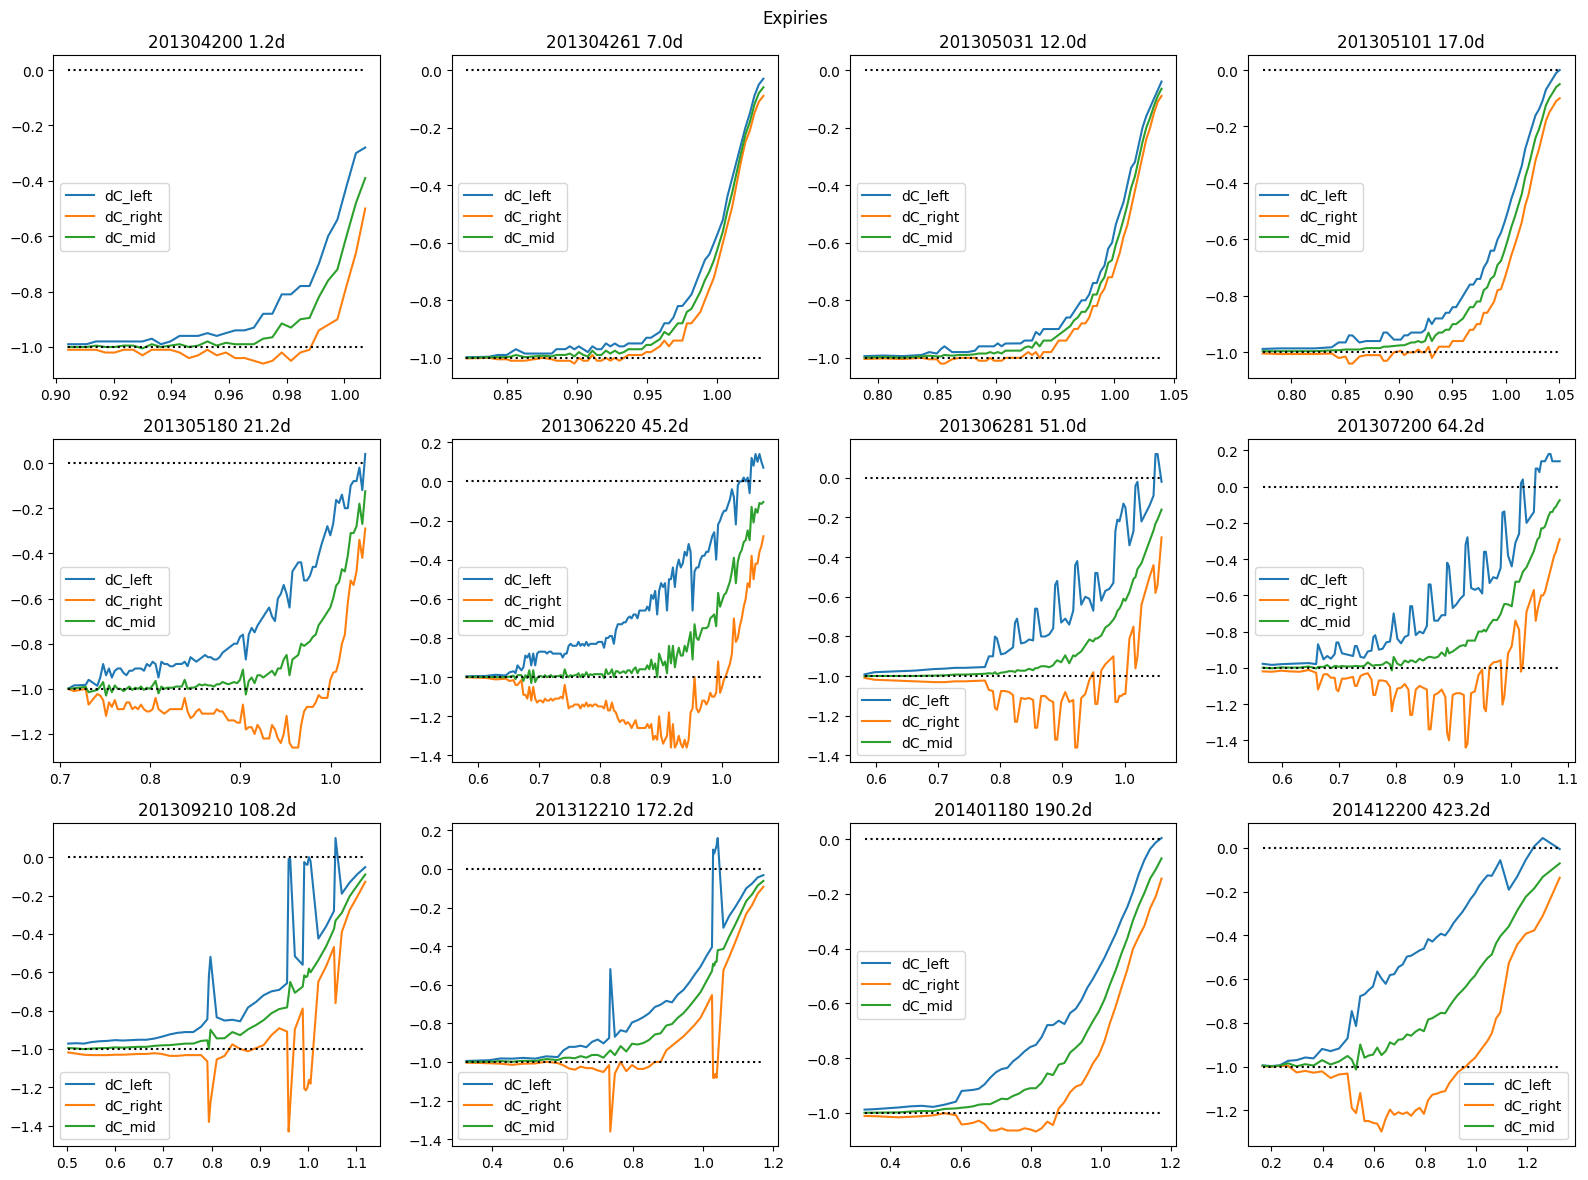

ValueError: If 'cvxpy_solver' is None, then 'cvxpy_solver_options' must also be None

In [1]:
if False:
    import os
    os.environ["QUANTDATA_CACHE_MODE"] = "off" # turns off global cache mode; good for testing, but do not use in general.

%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.utils.arbfree
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.arbfree

from datetime import date

from cdxcore.dynaplot import figure
from quantdata.widb.day import collect_raw_day, enrich_day, ExpiryFilter, RawDayFilter
from quantdata.widb.arbfree import mk_arb_free_day, MkArbFree
from quantdata.biz_calendar import next_business_day, DAYS_PER_YEAR
from cdxcore.verbose import Context
from IPython.display import display
import numpy as np

def test():
    ticker = "SPX"
    d      = next_business_day( date(2013, 4, 17), count_start=True )

    raw_day_filter = RawDayFilter()
    expiry_filter = ExpiryFilter()
    verbose = Context.all

    raw_day = collect_raw_day(ticker, d, raw_day_filter=raw_day_filter, verbose=verbose, raise_if_bad_day=False)

    enr_day = enrich_day(ticker, d, raw_day, raw_day_filter=raw_day_filter, expiry_filter=expiry_filter, verbose=verbose, raise_if_bad_day=False)

    expiry_ids = enr_day['expiry_id'].to_numpy()
    unids = np.unique( expiry_ids )
    with figure("Expiries", row_size=4, col_size=4, columns=4) as fig:
        for uid in unids:
            tte_y = enr_day['tte_y'][ expiry_ids == uid ].iloc[0]
            ax = fig.add_subplot(f"{uid} {tte_y*DAYS_PER_YEAR:.1f}d")

            mask = enr_day['expiry_id'] == uid
            strikes = enr_day['pure_strike'][mask].to_numpy()
            bids = enr_day['pure_bid_price'][mask].to_numpy()
            asks = enr_day['pure_ask_price'][mask].to_numpy()
            mids = (bids + asks) / 2.

            dC_left = ( asks[1:] - bids[:-1] ) / ( strikes[1:] - strikes[:-1] )
            dC_right = ( asks[:-1] - bids[1:] ) / ( strikes[:-1] - strikes[1:] )
            dC_mid = ( mids[1:] - mids[:-1] ) / ( strikes[1:] - strikes[:-1] )

            ax.plot(strikes[1:], dC_left, label="dC_left")
            ax.plot(strikes[1:], dC_right, label="dC_right")
            ax.plot(strikes[1:], dC_mid, label="dC_mid")
            ax.plot(strikes[1:], strikes[1:]*0-1., ":", color="black")
            ax.plot(strikes[1:], strikes[1:]*0, ":", color="black")
            ax.legend()

    arb_free = MkArbFree(cvxpy_solver_options={"time_limit":1})
    arb_free = mk_arb_free_day(ticker, d, enr_day, mk_arb_free=arb_free, raw_day_filter=raw_day_filter, expiry_filter=expiry_filter, verbose=verbose, raise_if_bad_day=False, override_cache_mode="off")

    display(arb_free)
    return arb_free

_ = test()